# Средняя траектория Надарая—Ватсона

## Импорты и параметры

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from my_lib import HankelMatrix, prepare_time_series, NWregression

pio.renderers.default = 'plotly_mimetype'
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})
START = 7220
T = 462
N_STEPS = 10
WINDOW = 454
N_COMPONENTS = 4
M = 900

## Запись ходьбы

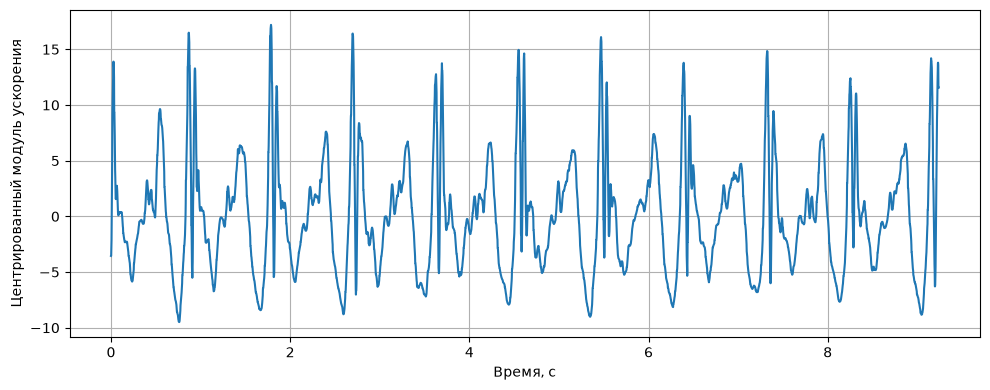

In [2]:
signal, time = prepare_time_series('data/long_walk_100_acc.csv')
x_acc = signal[START:START + T * N_STEPS]
plt.plot(np.arange(len(x_acc)) / 500, x_acc)
plt.xlabel('Время, с')
plt.ylabel('Центрированный модуль ускорения')
plt.tight_layout()
plt.show()

## Окна и начальные фазы

Каждой PCA-точке назначаем фазу по её индексу. Пары для регрессии: фаза → четыре координаты окна.

In [3]:
X_h = HankelMatrix(x_acc, WINDOW)
X_PCA = PCA(n_components=N_COMPONENTS, svd_solver='full').fit_transform(X_h)
X = (np.linspace(0, 2 * np.pi * (N_STEPS - 1), len(X_PCA)) % (2 * np.pi)).reshape(-1, 1)
Y = X_PCA
X_mean = np.linspace(0, 2 * np.pi, M).reshape(-1, 1)
print(f'Обучение: {X.shape} → {Y.shape}; запросы: {X_mean.shape}')

Обучение: (4167, 1) → (4167, 4); запросы: (900, 1)


## Регрессия

Модель усредняет координаты точек с близкими фазами. В этом опыте используется обычное расстояние между фазами и ядро четвёртой степени.

In [4]:
model = NWregression(p=2, h=0.03, kernel='quartic')
model.fit(X, Y)
regression = model.predict(X_mean)
assert regression.shape == (M, N_COMPONENTS)
assert np.isfinite(regression).all()

## Средняя кривая

In [5]:
fig = go.Figure()
fig.add_scatter3d(x=Y[:, 0], y=Y[:, 1], z=Y[:, 2],
                  mode='markers', marker_size=1, name='Окна')
fig.add_scatter3d(x=regression[:, 0], y=regression[:, 1], z=regression[:, 2],
                  mode='lines', line_width=6, name='Средняя траектория')
fig.update_layout(template='plotly_white', height=550,
                  scene=dict(xaxis_title='PC1', yaxis_title='PC2', zaxis_title='PC3'))
fig.show()

## Расстояния до модели

Минимальные L1-расстояния от окон до средней кривой отдельно сглаживаем по фазе.

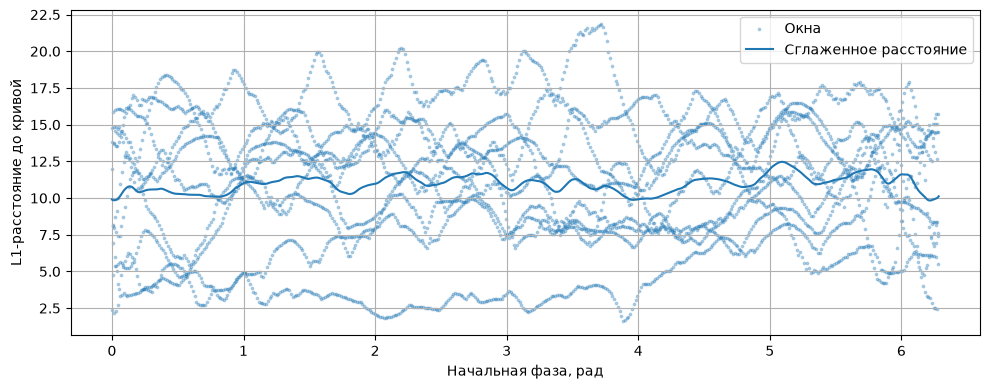

np.float64(10.964237247527333)

In [6]:
D_init = cdist(X_PCA, regression, metric='cityblock').min(axis=1).reshape(-1, 1)
model_D = NWregression(p=2, h=0.03, kernel='gaussian').fit(X, D_init)
regression_D = model_D.predict(X_mean)

plt.scatter(X[:, 0], D_init[:, 0], s=3, alpha=0.3, label='Окна')
plt.plot(X_mean[:, 0], regression_D[:, 0], label='Сглаженное расстояние')
plt.xlabel('Начальная фаза, рад')
plt.ylabel('L1-расстояние до кривой')
plt.legend()
plt.tight_layout()
plt.show()

D_init.mean()